### Imports

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from imblearn.datasets import fetch_datasets
from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold,
                                     cross_val_score)
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (balanced_accuracy_score, f1_score,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE, BorderlineSMOTE, SVMSMOTE
from imblearn.under_sampling import NearMiss

import seaborn as sns
sns.set_style('whitegrid')
np.random.seed(42)

### Load dataset

In [6]:
ozone = fetch_datasets(filter_data=('ozone_level',))['ozone_level']
X = ozone.data
y = ozone.target

TARGET_COLUMN = 'Target'

# --- KEY FIX: ozone_level labels are INVERTED vs what we assumed ---
# In fetch_datasets, ozone_level has:
#   y == -1 → 2463 samples (majority)
#   y == +1 →   73 samples (minority)
# So flip them so minority becomes -1 (matches the rest of the notebook)
y = -y

print(f"Shape: {X.shape}")
print(f"Class distribution: {np.bincount(y.astype(int) + 1)}")
print(f"  minority (-1): {sum(y==-1)}")
print(f"  majority (+1): {sum(y==1)}")
print(f"  imbalance ratio: {sum(y==1) / sum(y==-1):.1f}:1")
print(f"Class label column (per Table 4): '{TARGET_COLUMN}'")

Shape: (2536, 72)
Class distribution: [  73    0 2463]
  minority (-1): 73
  majority (+1): 2463
  imbalance ratio: 33.7:1
Class label column (per Table 4): 'Target'


### Stratified Train/Test Split + Scaling

In [7]:
# Stratified split preserves the 34:1 ratio in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Train class counts: {np.bincount(y_train.astype(int) + 1)}")
print(f"Test class counts:  {np.bincount(y_test.astype(int) + 1)}")

# Scale — fit on train ONLY, transform both
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)

Train: (1775, 72), Test: (761, 72)
Train class counts: [  51    0 1724]
Test class counts:  [ 22   0 739]


### Define the 5 sampling algorithms

In [8]:
# Define the 5 samplers for Variant 16
# Slot 4 is a hybrid → handled separately with Pipeline

samplers = {
    'SMOTE':             SMOTE(random_state=42),
    'Borderline-SMOTE2': BorderlineSMOTE(random_state=42, kind='borderline-2'),
    'NearMiss-3':        NearMiss(version=3, n_neighbors=3, n_neighbors_ver3=3),
    'SVMSMOTE':          SVMSMOTE(random_state=42),
}

print("Samplers for Variant 16:")
for i, name in enumerate(samplers, 1):
    print(f"  {i}. {name}")
print("  4. SMOTE + NearMiss-3  (custom hybrid via Pipeline)")

Samplers for Variant 16:
  1. SMOTE
  2. Borderline-SMOTE2
  3. NearMiss-3
  4. SVMSMOTE
  4. SMOTE + NearMiss-3  (custom hybrid via Pipeline)


### Baseline - No sampling (for comparison)

In [9]:
def evaluate_classifier(clf, X_train, y_train, X_test, y_test,
                        name='Model'):
    """Train and evaluate. Returns dict of metrics."""
    clf.fit(X_train, y_train)

    y_train_pred = clf.predict(X_train)
    y_test_pred  = clf.predict(X_test)

    # Minority class = -1 → we use pos_label=-1 for binary F1
    metrics = {
        'Model':             name,
        'Train BalAcc':      balanced_accuracy_score(y_train, y_train_pred),
        'Test  BalAcc':      balanced_accuracy_score(y_test,  y_test_pred),
        'Train F1 (min)':    f1_score(y_train, y_train_pred, pos_label=-1),
        'Test  F1 (min)':    f1_score(y_test,  y_test_pred,  pos_label=-1),
        'Test Recall (min)': __import__('sklearn.metrics', fromlist=['recall_score'])
                                .recall_score(y_test, y_test_pred, pos_label=-1),
        'Test Prec (min)':   __import__('sklearn.metrics', fromlist=['precision_score'])
                                .precision_score(y_test, y_test_pred, pos_label=-1),
    }
    return metrics, clf, y_test_pred


# Three classifiers we'll compare throughout
def make_classifiers():
    return {
        'KNN': KNeighborsClassifier(n_neighbors=5),
        'SVM': SVC(kernel='rbf', C=1.0, class_weight='balanced',
                   random_state=42),
        'RF':  RandomForestClassifier(n_estimators=200, class_weight='balanced',
                                      random_state=42, n_jobs=-1),
    }

# Baseline
baseline_results = []
for clf_name, clf in make_classifiers().items():
    m, _, _ = evaluate_classifier(clf, X_train_s, y_train, X_test_s, y_test,
                                  name=f'Baseline — {clf_name}')
    baseline_results.append(m)

baseline_df = pd.DataFrame(baseline_results)
print("=== BASELINE (no sampling) ===")
print(baseline_df.round(3).to_string(index=False))

=== BASELINE (no sampling) ===
         Model  Train BalAcc  Test  BalAcc  Train F1 (min)  Test  F1 (min)  Test Recall (min)  Test Prec (min)
Baseline — KNN         0.607         0.521           0.338           0.077              0.045            0.250
Baseline — SVM         0.965         0.773           0.457           0.272              0.636            0.173
 Baseline — RF         1.000         0.500           1.000           0.000              0.000            0.000


### Apply Each Sampler + Train Three Classifiers

In [10]:
# Collect all results
all_results = list(baseline_results)  # start with baseline

for sampler_name, sampler in samplers.items():
    print(f"\n{'='*60}\nSampler: {sampler_name}\n{'='*60}")

    # Balance ONLY the training set
    X_res, y_res = sampler.fit_resample(X_train_s, y_train)

    print(f"  Before: {np.bincount(y_train.astype(int) + 1)}")
    print(f"  After:  {np.bincount(y_res.astype(int) + 1)}")

    # Train each classifier on the balanced training data,
    # evaluate on the UNTOUCHED test set
    for clf_name, clf in make_classifiers().items():
        m, _, _ = evaluate_classifier(
            clf, X_res, y_res, X_test_s, y_test,
            name=f'{sampler_name} + {clf_name}'
        )
        all_results.append(m)

results_df = pd.DataFrame(all_results)
print("\n=== ALL RESULTS ===")
print(results_df.round(3).to_string(index=False))


Sampler: SMOTE
  Before: [  51    0 1724]
  After:  [1724    0 1724]

Sampler: Borderline-SMOTE2
  Before: [  51    0 1724]
  After:  [1724    0 1724]

Sampler: NearMiss-3
  Before: [  51    0 1724]
  After:  [51  0 51]

Sampler: SVMSMOTE
  Before: [  51    0 1724]
  After:  [1724    0 1724]

=== ALL RESULTS ===
                  Model  Train BalAcc  Test  BalAcc  Train F1 (min)  Test  F1 (min)  Test Recall (min)  Test Prec (min)
         Baseline — KNN         0.607         0.521           0.338           0.077              0.045            0.250
         Baseline — SVM         0.965         0.773           0.457           0.272              0.636            0.173
          Baseline — RF         1.000         0.500           1.000           0.000              0.000            0.000
            SMOTE + KNN         0.941         0.744           0.945           0.193              0.636            0.114
            SMOTE + SVM         0.976         0.718           0.976           0.272  

### Handle Varinat 16's Slot 4 - Custom Hybrid (SMOTE + NearMiss-3)

In [11]:
from imblearn.pipeline import Pipeline as ImbPipeline

# Slot 4: SMOTE + NearMiss-3
hybrid_steps = [
    ('over',  SMOTE(random_state=42)),
    ('under', NearMiss(version=3, n_neighbors=3)),
]
hybrid_sampler = ImbPipeline(steps=hybrid_steps)

print("Slot 4 — SMOTE + NearMiss-3 hybrid pipeline built")

# Fit the pipeline on the training set
X_res_hybrid, y_res_hybrid = hybrid_sampler.fit_resample(X_train_s, y_train)

print(f"  Before: {np.bincount(y_train.astype(int) + 1)}")
print(f"  After:  {np.bincount(y_res_hybrid.astype(int) + 1)}")

# Train each classifier
for clf_name, clf in make_classifiers().items():
    m, _, _ = evaluate_classifier(
        clf, X_res_hybrid, y_res_hybrid, X_test_s, y_test,
        name=f'SMOTE+NearMiss-3 + {clf_name}'
    )
    all_results.append(m)

results_df = pd.DataFrame(all_results)
print("\n=== ALL RESULTS (including hybrid) ===")
print(results_df.round(3).to_string(index=False))

Slot 4 — SMOTE + NearMiss-3 hybrid pipeline built
  Before: [  51    0 1724]
  After:  [1724    0 1724]

=== ALL RESULTS (including hybrid) ===
                  Model  Train BalAcc  Test  BalAcc  Train F1 (min)  Test  F1 (min)  Test Recall (min)  Test Prec (min)
         Baseline — KNN         0.607         0.521           0.338           0.077              0.045            0.250
         Baseline — SVM         0.965         0.773           0.457           0.272              0.636            0.173
          Baseline — RF         1.000         0.500           1.000           0.000              0.000            0.000
            SMOTE + KNN         0.941         0.744           0.945           0.193              0.636            0.114
            SMOTE + SVM         0.976         0.718           0.976           0.272              0.500            0.186
             SMOTE + RF         1.000         0.583           1.000           0.216              0.182            0.267
Borderline-SMOTE

### Results Table

In [12]:
# Sort for readability
results_sorted = results_df.sort_values(
    ['Test  BalAcc', 'Test  F1 (min)'], ascending=False
).reset_index(drop=True)

print("=== FINAL RESULTS (sorted by Test Balanced Accuracy) ===")
print(results_sorted.round(3).to_string(index=False))

# Save to CSV for the report
results_sorted.to_csv('lab7_8_results_variant16.csv', index=False)

=== FINAL RESULTS (sorted by Test Balanced Accuracy) ===
                  Model  Train BalAcc  Test  BalAcc  Train F1 (min)  Test  F1 (min)  Test Recall (min)  Test Prec (min)
         Baseline — SVM         0.965         0.773           0.457           0.272              0.636            0.173
        NearMiss-3 + RF         1.000         0.747           1.000           0.199              0.636            0.118
            SMOTE + KNN         0.941         0.744           0.945           0.193              0.636            0.114
 SMOTE+NearMiss-3 + KNN         0.941         0.744           0.945           0.193              0.636            0.114
       NearMiss-3 + SVM         0.863         0.735           0.848           0.208              0.591            0.126
            SMOTE + SVM         0.976         0.718           0.976           0.272              0.500            0.186
 SMOTE+NearMiss-3 + SVM         0.976         0.718           0.976           0.272              0.500 

### Bar Charts Comparing Balanced Accuracy and F1

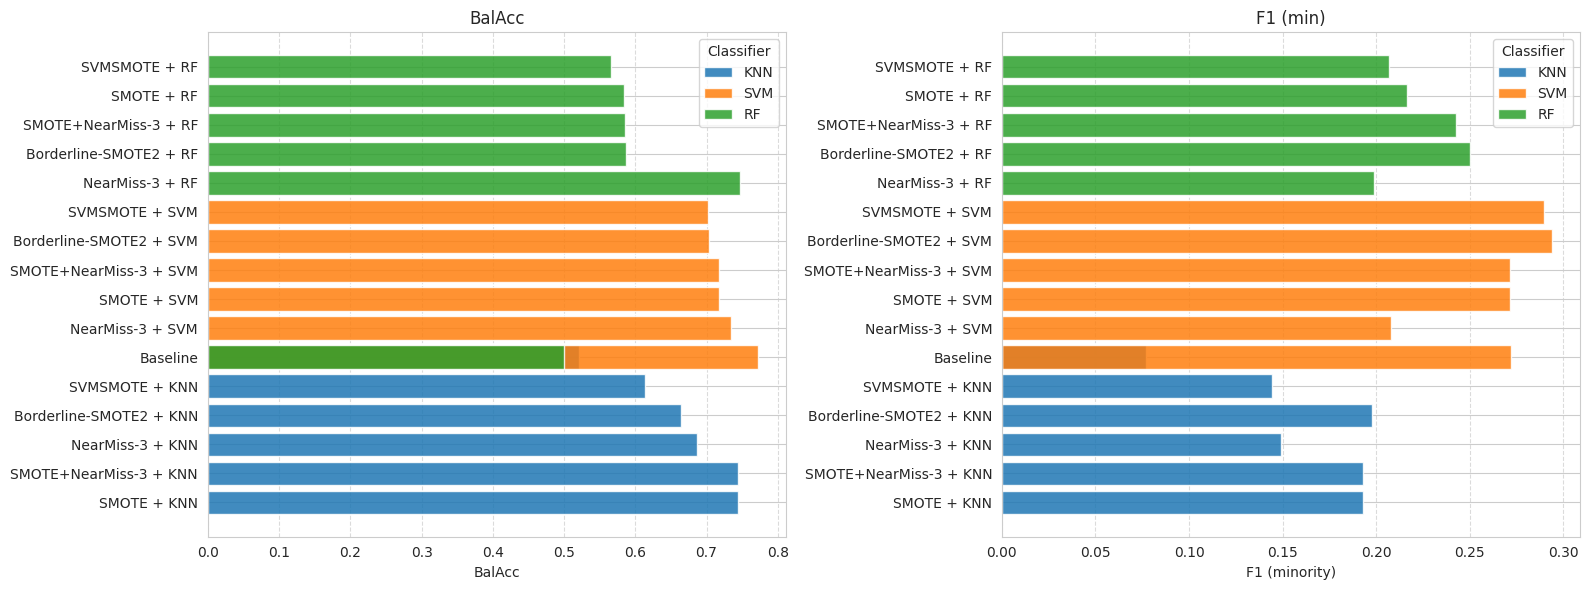

In [13]:
# Separate by classifier to make readable charts
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, metric in zip(axes, ['Test  BalAcc', 'Test  F1 (min)']):
    for i, clf_name in enumerate(['KNN', 'SVM', 'RF']):
        sub = results_sorted[results_sorted['Model'].str.endswith(clf_name)]
        bars = ax.barh([f"{r['Model'].split(' — ')[0]}" for _, r in sub.iterrows()],
                       sub[metric].values,
                       label=clf_name, alpha=0.85)
    ax.set_xlabel(metric.replace('Test  ', '').replace(' (min)', ' (minority)'))
    ax.set_title(metric.replace('Test  ', ''))
    ax.legend(title='Classifier')
    ax.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('lab7_8_metrics_variant16.png', dpi=150, bbox_inches='tight')
plt.show()

### Split Plots

In [ ]:
from sklearn.manifold import TSNE
import umap
import trimap
import pacmap

# Use the SMOTE-balanced training data for a vivid visualization
X_res_smote, y_res_smote = SMOTE(random_state=42).fit_resample(X_train_s, y_train)

# Compute four embeddings on this balanced data
embeddings = {}
embeddings['t-SNE (p=30)'] = TSNE(n_components=2, perplexity=30,
                                   init='pca', max_iter=1000,
                                   random_state=42).fit_transform(X_res_smote)
embeddings['t-SNE (p=50)'] = TSNE(n_components=2, perplexity=50,
                                   init='pca', max_iter=1000,
                                   random_state=42).fit_transform(X_res_smote)
embeddings['UMAP']         = umap.UMAP(n_components=2, n_neighbors=15,
                                       min_dist=0.1,
                                       random_state=42).fit_transform(X_res_smote)
embeddings['TriMap']       = trimap.TRIMAP(n_inliers=10, n_outliers=5,
                                           n_random=5, n_iters=400
                                           ).fit_transform(X_res_smote)
embeddings['PaCMAP']       = pacmap.PaCMAP(n_components=2, n_neighbors=10,
                                           MN_ratio=0.5, FP_ratio=2.0,
                                           random_state=42
                                           ).fit_transform(X_res_smote, init='pca')                                                                                                                                                                              

In [17]:
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.base import clone

def cv_sampler_plus_classifier(sampler, clf, X, y, n_splits=5, n_repeats=3):
    """
    CV pipeline: sampler(s) → classifier.
    Handles BOTH a single sampler AND an ImbPipeline of samplers
    by flattening the sampler's steps into the outer pipeline.
    """
    cv = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats,
                                 random_state=42)

    # Build the pipeline steps
    if isinstance(sampler, ImbPipeline):
        # Unpack the inner pipeline's steps (may be 1 or 2 samplers)
        inner_steps = [(f'smpl_{i}', clone(step))
                       for i, (_, step) in enumerate(sampler.steps)]
        steps = inner_steps + [('clf', clf)]
    else:
        steps = [('sampler', sampler), ('clf', clf)]

    pipe = ImbPipeline(steps=steps)

    bal_acc = cross_val_score(pipe, X, y,
                              scoring='balanced_accuracy',
                              cv=cv, n_jobs=-1)
    # F1 for the minority class only
    f1 = cross_val_score(pipe, X, y, scoring='f1',
                         cv=cv, n_jobs=-1)
    return bal_acc.mean(), f1.mean()

In [21]:
# --- Cell: Run CV for all samplers, build cv_df ---
cv_rows = []
for sampler_name, sampler in list(samplers.items()) + \
                              [('SMOTE+NearMiss-3', hybrid_sampler)]:
    print(f"Running CV: {sampler_name} ...")
    for clf_name, clf in make_classifiers().items():
        ba, f1 = cv_sampler_plus_classifier(
            sampler, clf, X_train_s, y_train
        )
        cv_rows.append({
            'Sampler': sampler_name,
            'Classifier': clf_name,
            'CV Balanced Acc': ba,
            'CV F1 (minority)': f1,
        })

cv_df = (pd.DataFrame(cv_rows)
           .sort_values('CV Balanced Acc', ascending=False)
           .reset_index(drop=True))

print("\n=== CROSS-VALIDATION RESULTS (Repeated Stratified 5-Fold × 3) ===")
print(cv_df.round(3).to_string(index=False))

cv_df.to_csv('lab7_8_cv_results_variant16.csv', index=False)

Running CV: SMOTE ...
Running CV: Borderline-SMOTE2 ...
Running CV: NearMiss-3 ...
Running CV: SVMSMOTE ...
Running CV: SMOTE+NearMiss-3 ...

=== CROSS-VALIDATION RESULTS (Repeated Stratified 5-Fold × 3) ===
          Sampler Classifier  CV Balanced Acc  CV F1 (minority)
       NearMiss-3        SVM            0.769             0.918
       NearMiss-3         RF            0.759             0.902
Borderline-SMOTE2        SVM            0.758             0.973
            SMOTE        SVM            0.755             0.966
 SMOTE+NearMiss-3        SVM            0.755             0.966
            SMOTE        KNN            0.753             0.917
 SMOTE+NearMiss-3        KNN            0.753             0.917
         SVMSMOTE        SVM            0.752             0.973
       NearMiss-3        KNN            0.741             0.892
         SVMSMOTE        KNN            0.738             0.944
Borderline-SMOTE2        KNN            0.732             0.948
         SVMSMOTE       

### Final Heatmap

cv_df shape: (15, 4)
Columns: ['Sampler', 'Classifier', 'CV Balanced Acc', 'CV F1 (minority)']
Samplers: ['NearMiss-3', 'Borderline-SMOTE2', 'SMOTE', 'SMOTE+NearMiss-3', 'SVMSMOTE']
Classifiers: ['SVM', 'RF', 'KNN']

✓ No NaNs — safe to pivot


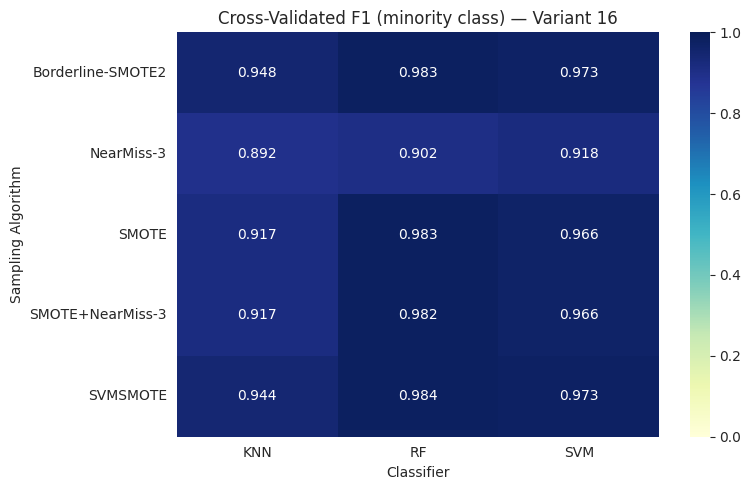

In [23]:
# --- Sanity check: cv_df must exist ---
assert 'cv_df' in dir(), \
    "cv_df is not defined — re-run the CV cell (Cell 11) first."

print(f"cv_df shape: {cv_df.shape}")
print(f"Columns: {cv_df.columns.tolist()}")
print(f"Samplers: {cv_df['Sampler'].unique().tolist()}")
print(f"Classifiers: {cv_df['Classifier'].unique().tolist()}")

# Check for missing values that would break pivot
if cv_df['CV F1 (minority)'].isna().any():
    print("\n⚠️  Warning: NaNs in 'CV F1 (minority)' column")
    print(cv_df[cv_df['CV F1 (minority)'].isna()])
else:
    print("\n✓ No NaNs — safe to pivot")
    
pivot = cv_df.pivot(index='Sampler',
                    columns='Classifier',
                    values='CV F1 (minority)')

plt.figure(figsize=(8, 5))
sns.heatmap(pivot, annot=True, fmt='.3f',
            cmap='YlGnBu', vmin=0, vmax=1)
plt.title('Cross-Validated F1 (minority class) — Variant 16')
plt.ylabel('Sampling Algorithm')
plt.xlabel('Classifier')
plt.tight_layout()
plt.savefig('lab7_8_heatmap_variant16.png', dpi=150)
plt.show()